In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')



/tmp/ipykernel_16/1274042804.py:7: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


In [2]:
print(train.shape)
print(test.shape)

(138701, 50)
(15000, 49)


In [3]:
train.head()

,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,...,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,...,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,...,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         32

In [5]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 49 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   TransactionID              15000 non-null  int64  
 1   AssetID                    15000 non-null  int64  
 2   ProductConfigID            15000 non-null  int64  
 3   DataOriginCode             15000 non-null  object 
 4   VendorPartnerID            15000 non-null  object 
 5   ManufactureYear            15000 non-null  int64  
 6   OperationalHoursMeter      8809 non-null   float64
 7   UtilizationTier            5356 non-null   object 
 8   TransactionDate            15000 non-null  object 
 9   Spec_FullDescriptor        15000 non-null  object 
 10  Spec_BaseClass             15000 non-null  object 
 11  Spec_SubClass              11006 non-null  object 
 12  Spec_ReleaseSeries         3505 non-null   object 
 13  Spec_VariantModifier       5609 non-null   obj

In [6]:
missing_value=train.isnull().sum().sort_values(ascending=False)
missing_value

col19                        138635
col18                        138635
col5                         128320
col4                         128320
col27                        123742
col28                        123742
col29                        119829
col30                        119829
col13                        115296
col14                        115296
col7                         115296
col6                         115296
col9                         115296
col8                         115296
col11                        115296
col3                         109448
Forks                        109382
Spec_ReleaseSeries           105805
col1                         104915
col12                        100337
col15                         96424
DrivetrainType                89956
UtilizationTier               88226
Spec_VariantModifier          86369
col20                         67685
col25                         67685
col21                         67685
col22                       

In [7]:
missing_percentage=(train.isnull().sum()/len(train))*100
missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)
missing_percentage

col18                    99.952416
col19                    99.952416
col4                     92.515555
col5                     92.515555
col28                    89.214930
col27                    89.214930
col30                    86.393753
col29                    86.393753
col14                    83.125572
col11                    83.125572
col13                    83.125572
col8                     83.125572
col9                     83.125572
col6                     83.125572
col7                     83.125572
col3                     78.909309
Forks                    78.861724
Spec_ReleaseSeries       76.282795
col1                     75.641127
col12                    72.340502
col15                    69.519326
DrivetrainType           64.856057
UtilizationTier          63.608770
Spec_VariantModifier     62.269919
col21                    48.799216
col20                    48.799216
col25                    48.799216
col23                    48.797774
col24               

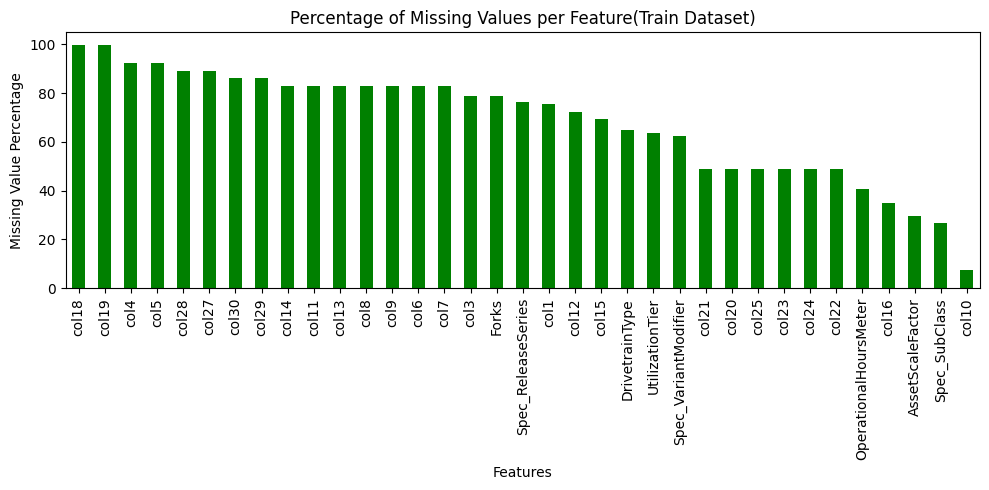

In [8]:
plt.figure(figsize=(10, 5))

missing_percentage.plot(kind='bar', color='green')

plt.title("Percentage of Missing Values per Feature(Train Dataset)")
plt.xlabel("Features")
plt.ylabel("Missing Value Percentage")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [9]:
train_missing_value=train.isnull().sum().sort_values(ascending=False)
train_missing_value

col19                        138635
col18                        138635
col5                         128320
col4                         128320
col27                        123742
col28                        123742
col29                        119829
col30                        119829
col13                        115296
col14                        115296
col7                         115296
col6                         115296
col9                         115296
col8                         115296
col11                        115296
col3                         109448
Forks                        109382
Spec_ReleaseSeries           105805
col1                         104915
col12                        100337
col15                         96424
DrivetrainType                89956
UtilizationTier               88226
Spec_VariantModifier          86369
col20                         67685
col25                         67685
col21                         67685
col22                       

In [10]:
missing_percentage=(test.isnull().sum()/len(test))*100
missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)
missing_percentage

col18                    99.906667
col19                    99.906667
col4                     92.520000
col5                     92.520000
col28                    89.593333
col27                    89.593333
col30                    86.940000
col29                    86.940000
col14                    82.813333
col11                    82.813333
col13                    82.813333
col8                     82.813333
col9                     82.813333
col6                     82.813333
col7                     82.813333
col3                     79.460000
Forks                    79.366667
Spec_ReleaseSeries       76.633333
col1                     75.333333
col12                    72.406667
col15                    69.753333
DrivetrainType           64.926667
UtilizationTier          64.293333
Spec_VariantModifier     62.606667
col21                    48.233333
col20                    48.233333
col25                    48.233333
col23                    48.226667
col24               

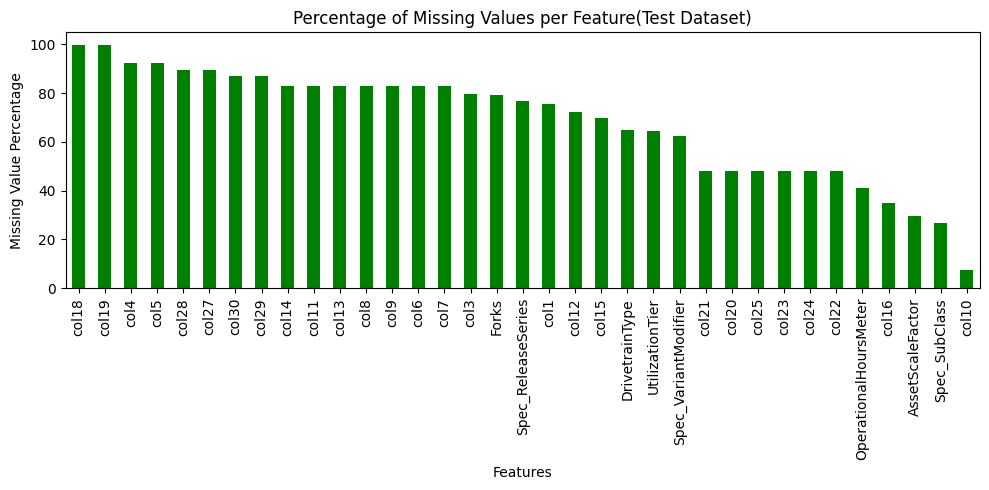

In [11]:
plt.figure(figsize=(10, 5))

missing_percentage.plot(kind='bar', color='green')

plt.title("Percentage of Missing Values per Feature(Test Dataset)")
plt.xlabel("Features")
plt.ylabel("Missing Value Percentage")

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [12]:
train_missing = set(train.columns[train.isnull().any()])
test_missing = set(test.columns[test.isnull().any()])

common_missing = train_missing & test_missing
train_only_missing = train_missing - test_missing
test_only_missing = test_missing - train_missing

print("Common:", sorted(common_missing))
print("Only Train:", sorted(train_only_missing))
print("Only Test:", sorted(test_only_missing))

Common: ['AssetScaleFactor', 'DrivetrainType', 'Forks', 'OperationalHoursMeter', 'Spec_ReleaseSeries', 'Spec_SubClass', 'Spec_VariantModifier', 'UtilizationTier', 'col1', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col3', 'col30', 'col4', 'col5', 'col6', 'col7', 'col8', 'col9']
Only Train: []
Only Test: []


In [13]:
train.nunique().sort_values(ascending=False)

TransactionID                138701
AssetID                      120111
OperationalHoursMeter         14643
TransactionDate                3676
ProductConfigID                3594
Spec_FullDescriptor            3505
Spec_BaseClass                 1249
TargetValue                     675
Spec_SubClass                   147
Spec_VariantModifier            132
Spec_ReleaseSeries              113
ManufactureYear                  68
FunctionalClassification         65
RegionCode                       53
VendorPartnerID                  31
col22                            27
col21                            18
col15                            15
col10                            11
col27                             9
DrivetrainType                    8
DataOriginCode                    6
col7                              6
AssetScaleFactor                  6
InventoryGroupDescription         6
InventoryGroupCategory            6
col28                             5
col1                        

Numberical and Categorical Features..

In [14]:
print("========== Numerical Features ==========")
print(train.describe())

print("\n========== Categorical Features ==========")
print(train.describe(include=['object']))

========== Numerical Features ==========
       TransactionID    TargetValue       AssetID  ProductConfigID  \
count   1.387010e+05  138701.000000  1.387010e+05    138701.000000   
mean    2.186276e+06   41521.874047  1.204814e+06      7286.421922   
std     1.128497e+06   26361.125948  5.287376e+05      7542.421537   
min     1.139309e+06    7500.000000  8.000000e+00        39.000000   
25%     1.465754e+06   20500.000000  1.007930e+06      1693.000000   
50%     1.751884e+06   35000.000000  1.246956e+06      3852.000000   
75%     2.372139e+06   57000.000000  1.495817e+06     11873.000000   
max     6.333410e+06  142000.000000  2.478476e+06     37209.000000   

       ManufactureYear  OperationalHoursMeter  
count    138701.000000           8.205800e+04  
mean       1891.640853           4.553719e+03  
std         306.992001           2.792204e+04  
min        1001.000000           0.000000e+00  
25%        1990.000000           0.000000e+00  
50%        1998.000000           1.62000

In [15]:
print("Target Variable Summary:")
print(train["TargetValue"].describe())

Target Variable Summary:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


In [16]:
print("Missing Values:", train["TargetValue"].isnull().sum())

Missing Values: 0


In [17]:
print("Unique Values:", train["TargetValue"].nunique())

Unique Values: 675


In [18]:
print("Skewness :", train["TargetValue"].skew())
print("Kurtosis :", train["TargetValue"].kurt())

Skewness : 0.9699963984208283
Kurtosis : 0.42390608021812515


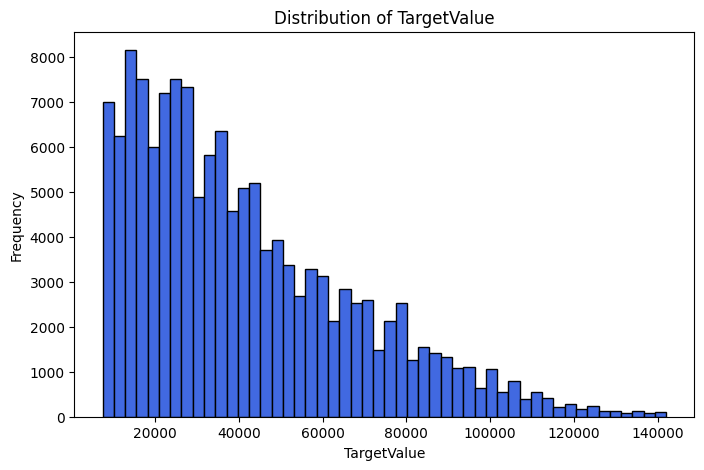

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(train["TargetValue"], bins=50, color="royalblue", edgecolor="black")

plt.title("Distribution of TargetValue")
plt.xlabel("TargetValue")
plt.ylabel("Frequency")

plt.show()